# 🌧️ Rainfall Prediction System - Model Development Notebook

Predict whether it will rain **tomorrow** (`RainTomorrow`) from today's weather observations.

**Pipeline in this notebook**
1. Load & inspect the data  2. Clean it  3. Analyse class imbalance & missing values  4. Exploratory analysis
5. Chronological and stratified train/test splits  6. Compare six models with 5-fold stratified CV
7. Evaluate on the hold-out set (accuracy, precision, recall, F1, ROC-AUC, confusion matrix)  8. Pick the best model

> The notebook uses `data/weatherAUS.csv` if it exists; otherwise it falls back to a synthetic dataset with the same schema (see `data/README.md`).

In [1]:
import sys, warnings, logging
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))          # make the `src` package importable
warnings.filterwarnings("ignore")
logging.basicConfig(level=logging.INFO, format="%(message)s")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

from src import config, visualize as viz
from src.data_loader import load_raw_data, clean_data, get_xy, split_data, class_balance
from src.models import build_all_models
from src.evaluate import compare_models, select_best_model

pd.set_option("display.max_columns", 40, "display.width", 200)

## 1. Load the data

In [2]:
raw, source = load_raw_data()
print("Source:", source)
print("Shape :", raw.shape)
raw.head()

data/weatherAUS.csv not found - using SYNTHETIC data with the same schema. Download the real dataset (see data/README.md) for real-world results.


Source: synthetic dataset (same schema as weatherAUS)
Shape : (29216, 23)


,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,WindDir3pm,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow
0,2008-01-01,Sydney,18.6,27.2,0.0,NaN,7.8,ESE,40.0,W,SW,18.0,26.0,76.0,67.0,1015.5,1013.7,5.0,4.0,21.5,26.1,No,No
1,2008-01-02,Sydney,14.0,28.2,0.0,NaN,14.0,SSE,44.0,SSW,SE,22.0,15.0,65.0,55.0,1016.0,1016.1,2.0,3.0,22.1,26.8,No,No
2,2008-01-03,Sydney,18.6,29.6,0.0,8.2,7.3,ESE,35.0,NaN,SE,14.0,12.0,80.0,64.0,1015.7,1015.3,NaN,NaN,23.6,28.5,No,Yes
3,2008-01-04,Sydney,21.3,28.4,17.0,4.6,NaN,SSW,43.0,S,SSW,13.0,17.0,62.0,70.0,1015.1,1013.2,7.0,5.0,23.1,26.8,Yes,No
4,2008-01-05,Sydney,16.8,25.6,0.0,NaN,NaN,SE,44.0,NE,SW,21.0,22.0,60.0,43.0,1018.8,1018.5,NaN,NaN,22.1,23.7,No,No


## 2. Data cleaning
Row-level cleaning only (parse dates, drop rows without a label, remove duplicates, null impossible values). **Imputation and scaling are deliberately left to the model pipeline** so they are fitted on training data only.

In [3]:
df = clean_data(raw)
print(f"{len(raw):,} raw rows -> {len(df):,} rows after cleaning")
print("Date range:", df['Date'].min().date(), "->", df['Date'].max().date())
df.describe().T.round(2)

29,216 raw rows -> 28,630 rows after cleaning
Date range: 2008-01-01 -> 2017-12-29


,count,mean,min,25%,50%,75%,max,std
Date,28630,2012-12-28 20:59:26.049598,2008-01-01 00:00:00,2010-07-01 00:00:00,2012-12-28 00:00:00,2015-06-29 00:00:00,2017-12-29 00:00:00,NaN
MinTemp,28313.0,12.667432,-9.3,7.4,12.8,18.1,36.8,7.263206
MaxTemp,28366.0,23.173733,0.2,17.9,23.5,28.6,43.0,7.067559
Rainfall,28122.0,1.667179,0.0,0.0,0.0,0.8,74.6,4.145673
Evaporation,16539.0,5.030504,0.0,3.0,5.0,7.0,16.6,2.766146
Sunshine,17771.0,8.495566,0.0,6.2,8.6,11.0,14.0,3.337115
WindGustSpeed,26929.0,37.981581,9.0,30.0,38.0,46.0,89.0,12.140399
WindSpeed9am,28332.0,13.674008,0.0,9.0,14.0,18.0,44.0,6.197704
WindSpeed3pm,28043.0,17.517348,0.0,13.0,17.0,22.0,51.0,7.131165
Humidity9am,28076.0,68.91003,10.0,58.0,69.0,80.0,100.0,15.473813


## 3. Class imbalance

{'no_rain': 22030, 'rain': 6600, 'rain_pct': 23.05, 'imbalance_ratio': 3.34}


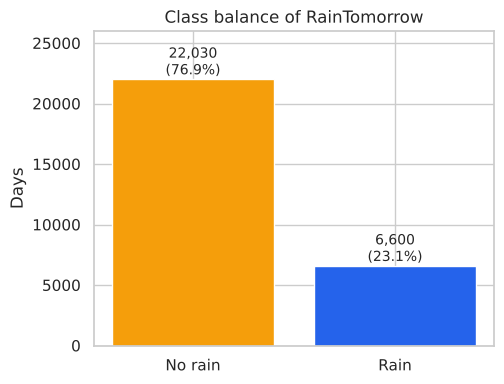

In [4]:
X_all, y_all = get_xy(df)
print(class_balance(y_all))
viz.plot_class_balance(y_all);

Roughly three dry days for every rainy day, so plain accuracy is misleading (always predicting 'no rain' would already score ~77%). We therefore use class weights during training and judge models on **precision, recall, F1 and ROC-AUC**, not accuracy alone.

## 4. Missing values

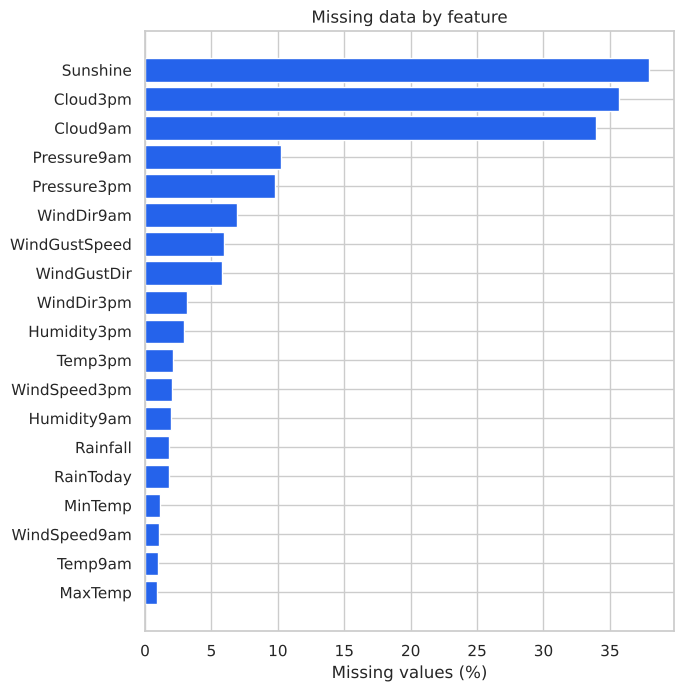

In [5]:
viz.plot_missing_values(df);

`Sunshine` and the cloud-cover variables are missing most often. They are imputed with the **training-set median** (numeric) or **most frequent value** (categorical) inside the pipeline.

## 5. Exploratory analysis

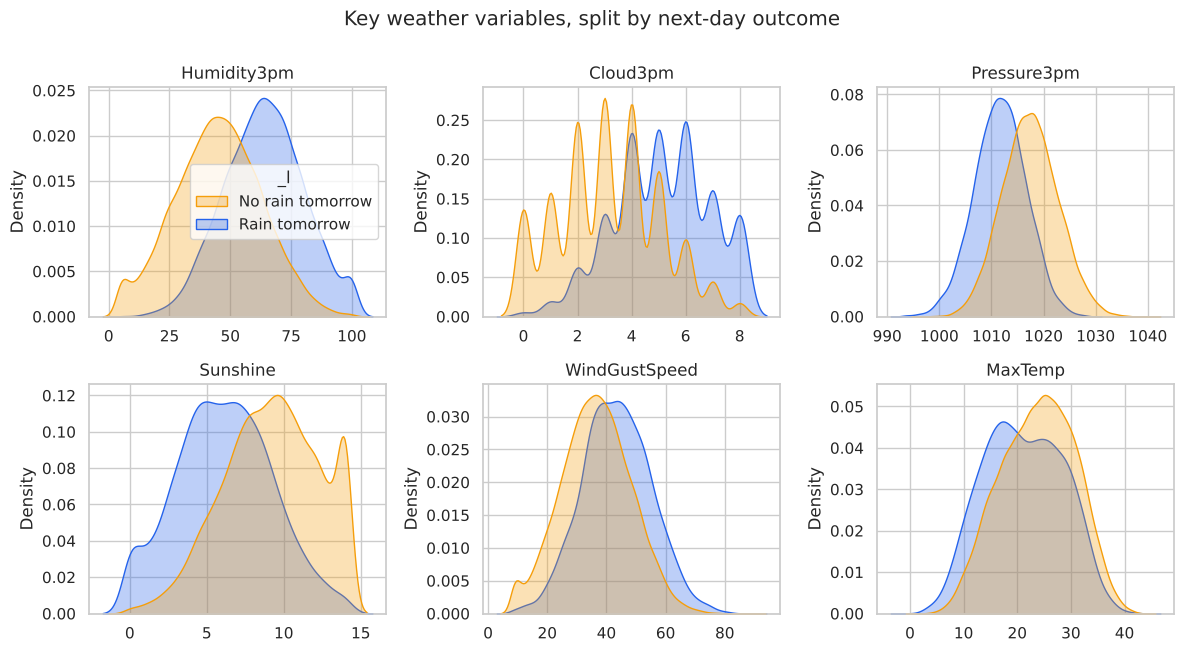

In [6]:
viz.plot_key_distributions(df);

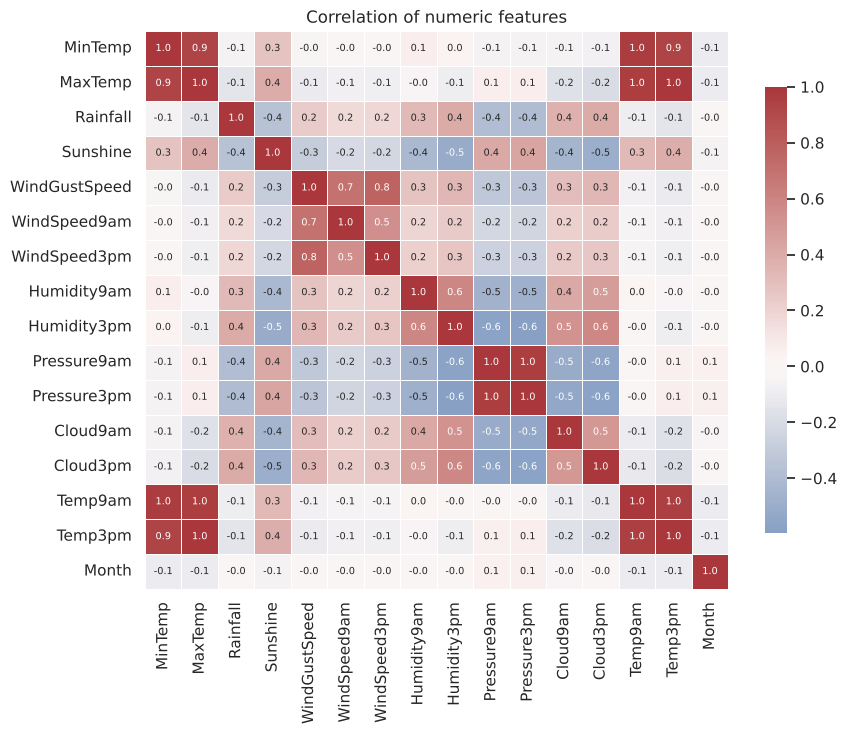

In [7]:
viz.plot_correlation(df);

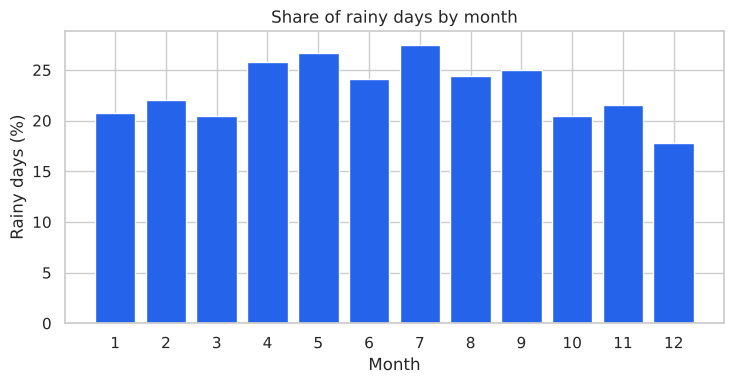

In [8]:
viz.plot_monthly_rain(df);

## 6. Train / test split
* **Chronological** (primary): train on the earliest 80% of dates, test on the most recent 20% - this mimics real forecasting.
* **Stratified random** (secondary): keeps the rain ratio identical in both sets, but mixes neighbouring days between train and test.

In [9]:
X_tr, X_te, y_tr, y_te = split_data(df, "chronological")
print("Chronological: train", X_tr.shape, "| test", X_te.shape)
print("  train dates up to", df.loc[X_tr.index, 'Date'].max().date(), "| test dates from", df.loc[X_te.index, 'Date'].min().date())
print("  rain share  train %.3f | test %.3f" % (y_tr.mean(), y_te.mean()))

Xs_tr, Xs_te, ys_tr, ys_te = split_data(df, "stratified")
print("Stratified   : train", Xs_tr.shape, "| test", Xs_te.shape)
print("  rain share  train %.3f | test %.3f" % (ys_tr.mean(), ys_te.mean()))

Chronological: train (22909, 21) | test (5721, 21)
  train dates up to 2015-12-29 | test dates from 2015-12-30
  rain share  train 0.228 | test 0.242
Stratified   : train (22904, 21) | test (5726, 21)
  rain share  train 0.231 | test 0.231


## 7. Leakage check
All preprocessing lives **inside** the sklearn `Pipeline`, so it is re-fitted on training rows only (and inside every CV fold). Quick proof - the fitted imputer statistics equal the *training* medians:

In [10]:
from src.models import build_model
probe = build_model("Logistic Regression").fit(X_tr, y_tr)
imp = probe.named_steps["preprocess"].named_transformers_["num"].named_steps["impute"]
print("Imputer medians == TRAIN medians:", np.allclose(imp.statistics_, X_tr[config.NUMERIC_FEATURES].median()))
print("Imputer medians == FULL-data medians:", np.allclose(imp.statistics_, X_all[config.NUMERIC_FEATURES].median()))

Imputer medians == TRAIN medians: True
Imputer medians == FULL-data medians: False


## 8. Train & compare the six models (5-fold stratified CV + hold-out test)
*SVM cross-validation takes a couple of minutes.*

In [11]:
models = build_all_models(y_tr)
results, fitted = compare_models(models, X_tr, X_te, y_tr, y_te, do_cv=True)
best_name = select_best_model(results)
print("\nBest model by 5-fold CV ROC-AUC:", best_name)
cols = ["model", "cv_roc_auc_mean", "cv_roc_auc_std", "cv_f1_mean",
        "test_accuracy", "test_precision", "test_recall", "test_f1", "test_roc_auc", "seconds"]
results[cols].round(3).sort_values("cv_roc_auc_mean", ascending=False).reset_index(drop=True)

[Logistic Regression] running 5-fold stratified CV ...


[Logistic Regression] fitting on full training set ...


[Logistic Regression] test acc=0.781 f1=0.623 auc=0.851 (2.3s)


[Decision Tree] running 5-fold stratified CV ...


[Decision Tree] fitting on full training set ...


...

[XGBoost] running 5-fold stratified CV ...


[XGBoost] fitting on full training set ...


[XGBoost] test acc=0.783 f1=0.621 auc=0.850 (4.2s)



Best model by 5-fold CV ROC-AUC: Logistic Regression


,model,cv_roc_auc_mean,cv_roc_auc_std,cv_f1_mean,test_accuracy,test_precision,test_recall,test_f1,test_roc_auc,seconds
0,Logistic Regression,0.852,0.004,0.605,0.781,0.535,0.745,0.623,0.851,2.3
1,XGBoost,0.850,0.003,0.604,0.783,0.538,0.735,0.621,0.850,4.2
2,Random Forest,0.849,0.004,0.621,0.814,0.609,0.653,0.630,0.852,23.4
3,SVM,0.831,0.004,0.614,0.790,0.552,0.714,0.622,0.838,163.1
4,Decision Tree,0.830,0.005,0.596,0.795,0.564,0.682,0.618,0.832,1.2
5,KNN,0.829,0.006,0.541,0.814,0.662,0.474,0.552,0.832,4.2


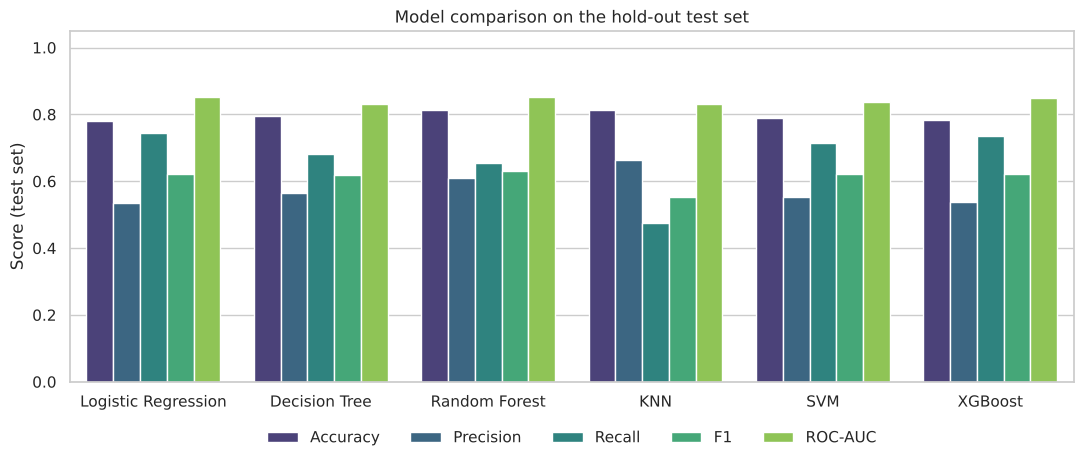

In [12]:
viz.plot_model_comparison(results);

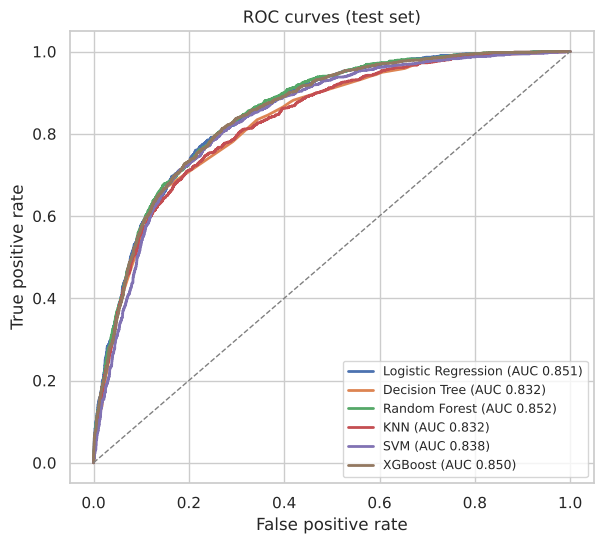

In [13]:
viz.plot_roc_curves(fitted, X_te, y_te);

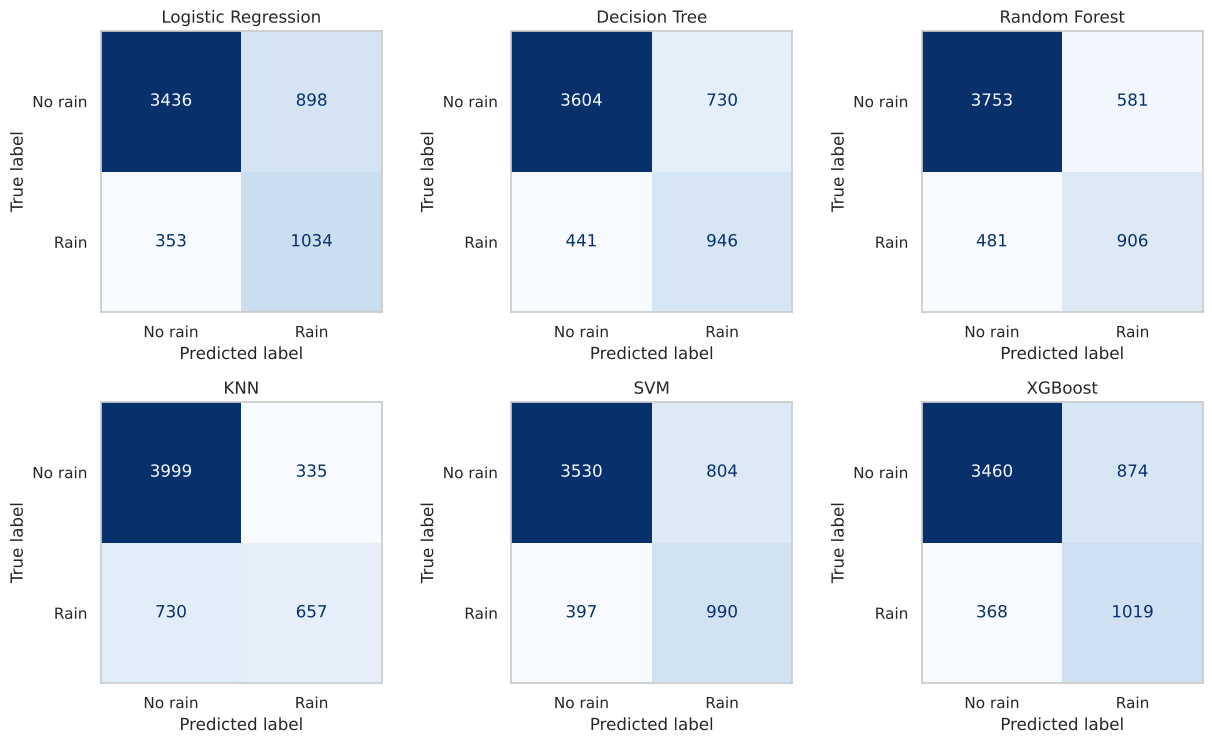

In [14]:
viz.plot_confusion_matrices(fitted, X_te, y_te);

## 9. Same models on a stratified random split (for comparison)

In [15]:
s_results, _ = compare_models(build_all_models(ys_tr), Xs_tr, Xs_te, ys_tr, ys_te, do_cv=False)
s_results[["model", "test_accuracy", "test_precision", "test_recall", "test_f1", "test_roc_auc"]].round(3)

[Logistic Regression] fitting on full training set ...


[Logistic Regression] test acc=0.780 f1=0.604 auc=0.846 (0.4s)


[Decision Tree] fitting on full training set ...


[Decision Tree] test acc=0.792 f1=0.601 auc=0.829 (0.3s)


[Random Forest] fitting on full training set ...


...

[SVM] fitting on full training set ...


[SVM] test acc=0.787 f1=0.603 auc=0.829 (38.7s)


[XGBoost] fitting on full training set ...


[XGBoost] test acc=0.779 f1=0.601 auc=0.845 (0.8s)


,model,test_accuracy,test_precision,test_recall,test_f1,test_roc_auc
0,Logistic Regression,0.780,0.517,0.727,0.604,0.846
1,Decision Tree,0.792,0.538,0.680,0.601,0.829
2,Random Forest,0.812,0.584,0.642,0.612,0.843
3,KNN,0.822,0.654,0.483,0.556,0.824
4,SVM,0.787,0.529,0.702,0.603,0.829
5,XGBoost,0.779,0.515,0.722,0.601,0.845


## 10. What drives the best model?

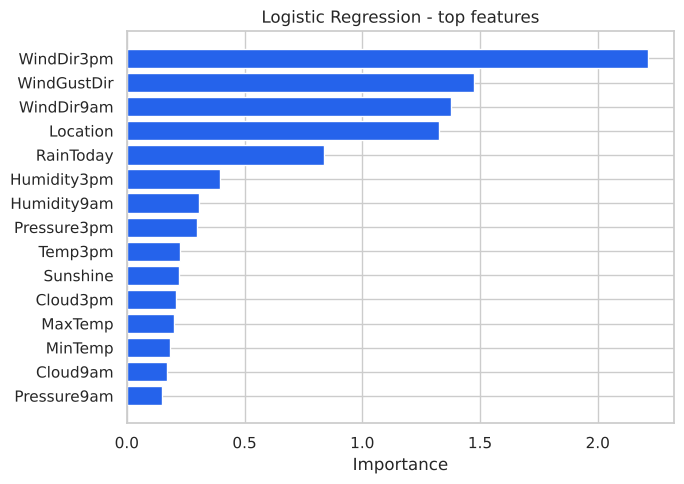

In [16]:
viz.plot_feature_importance(fitted[best_name], title=f'{best_name} - top features');

## 11. Try a prediction

In [17]:
sample = pd.DataFrame([{
    "Location": "Sydney", "MinTemp": 16.5, "MaxTemp": 21.0, "Rainfall": 12.4, "Sunshine": 1.5,
    "WindGustSpeed": 54, "WindSpeed9am": 22, "WindSpeed3pm": 30, "Humidity9am": 90, "Humidity3pm": 85,
    "Pressure9am": 1006, "Pressure3pm": 1004, "Cloud9am": 7, "Cloud3pm": 8, "Temp9am": 18, "Temp3pm": 19.5,
    "Month": 6, "WindGustDir": "SE", "WindDir9am": "SE", "WindDir3pm": "SSE", "RainToday": "Yes",
}])[config.FEATURES]
p = fitted[best_name].predict_proba(sample)[0, 1] if hasattr(fitted[best_name], "predict_proba") else float("nan")
print(f"{best_name}: probability of rain tomorrow = {p:.1%}")

Logistic Regression: probability of rain tomorrow = 97.3%


## 12. Conclusions
* Models were selected with **5-fold stratified cross-validation on the training period only**; the test period was never used for selection.
* Look at **ROC-AUC and F1** (not just accuracy) because of the class imbalance. Choosing a different probability threshold trades precision for recall - useful if missing a rainy day is costlier than a false alarm (e.g. flood warnings).
* The winner here is whichever model tops the table above. **On the synthetic demo data a linear model is hard to beat because the data was generated that way; on the real `weatherAUS.csv`, tree ensembles (Random Forest / XGBoost) typically lead.** Re-run this notebook (or `python -m src.train`) after adding the real data.